# OPEN leaf — SMART rosette trait extraction on the author-bundled sample

**Paper:** Mendoza-Cozatl et al., *OPEN leaf: an open-source cloud-based phenotyping system for tracking dynamic changes at leaf-specific resolution in Arabidopsis*, The Plant Journal (2023), doi:[10.1111/tpj.16449](https://doi.org/10.1111/tpj.16449) (preprint: bioRxiv 2021.12.17.472861).

**Scope (one-example demonstration):** run the authors' **SMART** pipeline (Speedy Measurement of Arabidopsis Rosette Traits, [Computational-Plant-Science/SMART](https://github.com/Computational-Plant-Science/SMART), pinned commit `7d3fe4151b434bdf03de2b18919955a8a9dd1fc1`) on the **author-bundled sample image** `sample_test/fad7_12.jpg`, producing the rosette segmentation mask, dominant-color clustering, and the `trait.xlsx` table exactly as the paper's *Image processing using SMART* section describes (parameter-free color clustering + watershed-based leaf counting). This is a partial demonstration of the paper: the OPEN leaf hardware, C# controller, cloud/Slack integration and the treatment time-course experiments are **not** reproduced. One example does not verify dataset-level paper results.

**実行内容（日本語）:** 著者提供のSMARTパイプラインを、リポジトリ同梱のサンプル画像 `fad7_12.jpg` に対してコミット固定で実行し、ロゼットのセグメンテーション、優勢色クラスタリング、`trait.xlsx` 形質表を再現します。ハードウェア・クラウド連携・処理系実験は対象外です。

**Execution status:** this notebook is executed top-to-bottom on a fresh Google Colab **CPU** runtime (no GPU is needed: the pipeline is classical computer vision plus one small u2net CPU inference). All dataset/weight downloads happen inside this notebook.

**Transparency note:** the author code is run unmodified **except** a 3-line NumPy-2/skimage-0.25 compatibility patch (shown as a diff below). **AI-assisted compatibility patch; the authors did not provide this Colab adaptation. The executed example and listed checks were validated, but untested behavior is not guaranteed.** / 著者コードを無修正で実行しますが、NumPy 2互換のため3行の最小パッチを表示付きで適用しています。

## Runtime selection

Select **Runtime → Change runtime type → CPU** (the default free runtime). GPU is not used by any step of SMART: color clustering, morphology, watershed, and the optional u2net background removal all run on CPU.

**Expected cost (measured on the validation run, 2026-10-27):** ≈10–15 min end to end; downloads ≈90 KB of code, the 5.7 MB sample image, the author reference outputs (<20 MB), and a ≈1 GB u2net model on the first `rembg` call (cached for the session).

**実行時間の目安:** 全体で10〜15分、初回のu2netモデル取得を含みます。

## Environment report

Print the interpreter and the scientific stack versions actually used, so the executed outputs record the true environment. Japanese: 実行環境のバージョンを記録します。

In [ ]:
import sys, platform
print(sys.version)
print(platform.platform())
import numpy, scipy, cv2, skimage, sklearn
for m in (numpy, scipy, cv2, skimage, sklearn):
    print(m.__name__, m.__version__)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Linux-6.6.159+-x86_64-with-glibc2.39


numpy 2.1.3
scipy 1.16.3
cv2 5.0.0
skimage 0.25.2
sklearn 1.6.1


## Dependency setup

The author Dockerfile pins `scikit-image==0.19.3`, which has no wheels for the current Colab Python 3.13 runtime, so that pin cannot be honored here. Every API the pipeline uses was **verified present** in the Colab-preinstalled scientific stack (numpy 2.x, scikit-image 0.25.x, OpenCV 5.x); only `rembg` (u2net background removal, used by the author script's default `-ai 1` mode) needs installing. Japanese: ColabのPython 3.13では著者Dockerfileのscikit-image 0.19.3ピンが使えないため、事前インストール済みスタックを利用し、rembgのみ追加インストールします。

In [ ]:
%pip install -q "rembg[cpu]"
print("install done")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


install done


**Verify the imports and the exact API surface** the author script touches, failing loudly if anything is missing (guards against silent future Colab image changes). Japanese: パイプラインが使うAPIの存在を確認します。

In [ ]:
import importlib, skimage, skimage.color, skimage.feature, skimage.morphology, skimage.segmentation, skimage.measure
for m in ("rembg", "openpyxl", "imutils", "psutil", "tabulate"):
    importlib.import_module(m); print(m, "OK", getattr(importlib.import_module(m), "__version__", ""))
checks = [(skimage.color, "deltaE_cie76"), (skimage.feature, "peak_local_max"),
          (skimage.morphology, "medial_axis"), (skimage.segmentation, "clear_border"),
          (skimage.segmentation, "watershed"), (skimage.measure, "regionprops")]
missing = [n for mod, n in checks if not hasattr(mod, n)]
assert not missing, f"missing skimage APIs: {missing}"
print("skimage API surface OK")

rembg OK 2.0.86


openpyxl OK 3.1.5
imutils OK 0.5.4
psutil OK 5.9.5
tabulate OK 0.9.0
skimage API surface OK


## Fetch the pinned author code

Only two source files are needed: `smart_release.py` (the release entry point) and `utils.py` (imported by it). They are fetched from the pinned commit `7d3fe4151b434bdf03de2b18919955a8a9dd1fc1` via raw URLs and byte counts are reported. Japanese: 著者コード2ファイルをコミット固定で取得します。

In [ ]:
import urllib.request, pathlib
COMMIT = "7d3fe4151b434bdf03de2b18919955a8a9dd1fc1"
RAW = "https://raw.githubusercontent.com/Computational-Plant-Science/SMART/" + COMMIT
code_dir = pathlib.Path("/content/smart_run/code"); code_dir.mkdir(parents=True, exist_ok=True)
for name in ("smart_release.py", "utils.py"):
    data = urllib.request.urlopen(f"{RAW}/{name}").read()
    (code_dir / name).write_bytes(data)
    (code_dir / (name + ".orig")).write_bytes(data)  # keep an untouched copy for the diff
    print(name, len(data), "bytes from commit", COMMIT[:12])

smart_release.py 77656 bytes from commit 7d3fe4151b43
utils.py 7656 bytes from commit 7d3fe4151b43


## Fetch the bundled sample input and verify it

`sample_test/fad7_12.jpg` is the authors' own bundled top-view Arabidopsis rosette image. Its **git blob SHA-1** is checked against the pinned repository tree, proving byte-identical download. Japanese: サンプル画像を取得し、git blob SHA-1で同一性を検証します。

In [ ]:
import hashlib, urllib.request, pathlib
in_dir = pathlib.Path("/content/smart_run/input"); in_dir.mkdir(parents=True, exist_ok=True)
img_path = in_dir / "fad7_12.jpg"
data = urllib.request.urlopen(f"{RAW}/sample_test/fad7_12.jpg").read()
img_path.write_bytes(data)
blob_sha = hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()
print("fad7_12.jpg:", len(data), "bytes; git blob sha1:", blob_sha)
assert blob_sha == "97adabe6ca49ff65297a5e17e23d66556e732913", "blob sha mismatch"
import cv2
img = cv2.imread(str(img_path))
print("decoded:", None if img is None else img.shape)

fad7_12.jpg: 5721991 bytes; git blob sha1: 97adabe6ca49ff65297a5e17e23d66556e732913
decoded: (1848, 4000, 3)


## Input preview

Downsampled view of the actual sample (a 4000×1848 px top-view Arabidopsis rosette on a dark background, as required by the SMART imaging protocol). Japanese: サンプル画像のプレビュー（縮小表示）。

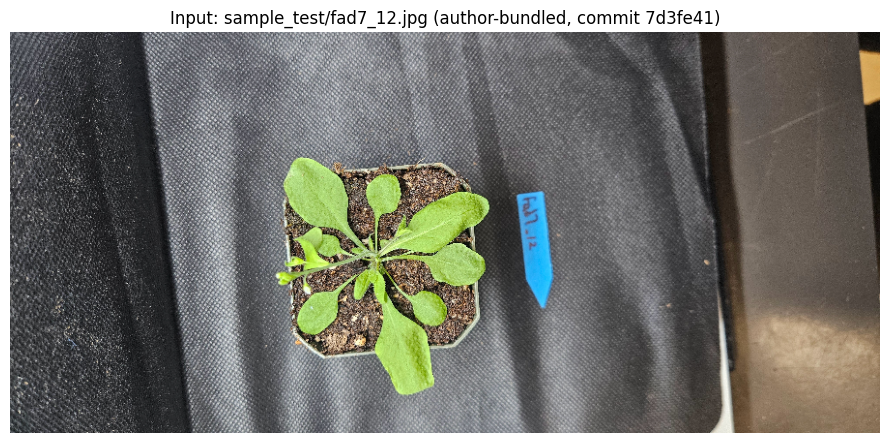

In [ ]:
import cv2, matplotlib.pyplot as plt
rgb = cv2.cvtColor(cv2.imread("/content/smart_run/input/fad7_12.jpg"), cv2.COLOR_BGR2RGB)
scale = 900 / max(rgb.shape[:2])
small = cv2.resize(rgb, (int(rgb.shape[1]*scale), int(rgb.shape[0]*scale)))
plt.figure(figsize=(9, 4.5))
plt.imshow(small); plt.axis("off")
plt.title("Input: sample_test/fad7_12.jpg (author-bundled, commit 7d3fe41)")
plt.tight_layout(); plt.savefig("/content/smart_run/input_preview.png", dpi=120); plt.show()

## Minimal compatibility patch (documented)

The author script predates NumPy 2 and scikit-image 0.25. Three behavior-preserving edits are applied to a copy (`smart_release_patched.py`); the untouched original stays beside it:
1. `smart_release.py` L1834 and L1490: `float()` on shape-`(1,)` arrays raises `TypeError` under NumPy 2 — replaced with the same scalar element.
2. `watershed_seg` L668: `peak_local_max(..., indices=False)` no longer accepts `indices` in scikit-image ≥0.20 — the boolean peak mask is built explicitly (same peaks, `exclude_border=False` preserved).

**AI-assisted patch — values are unchanged, only deprecated call styles updated.** Japanese: NumPy 2/skimage 0.25互換の最小パッチ（動作は不変）をコピーに適用します。

In [ ]:
import pathlib, difflib
code_dir = pathlib.Path("/content/smart_run/code")
src = (code_dir / "smart_release.py").read_text()
patched = src
patched = patched.replace("float(color_value_reshape[:,0]/255.0)", "float(color_value_reshape[0,0]/255.0)")
patched = patched.replace("float(color_value_reshape[:,1]/255.0)", "float(color_value_reshape[0,1]/255.0)")
patched = patched.replace("float(color_value_reshape[:,2]/255.0)", "float(color_value_reshape[0,2]/255.0)")
patched = patched.replace("diff_value = float(diff)", "diff_value = float(np.asarray(diff).reshape(-1)[0])")
patched = patched.replace(
    "localMax = peak_local_max(D, indices = False, min_distance = min_distance_value,  labels = thresh)",
    "peaks = peak_local_max(D, min_distance = min_distance_value, labels = thresh, exclude_border = False)\n"
    "    localMax = np.zeros(D.shape, dtype = bool)\n"
    "    localMax[tuple(peaks.T)] = True")
assert patched != src, "patch did not apply"
(code_dir / "smart_release_patched.py").write_text(patched)
for line in difflib.unified_diff(src.splitlines(), patched.splitlines(), lineterm="", n=0):
    print(line)

--- 
+++ 
@@ -668 +668,3 @@
-    localMax = peak_local_max(D, indices = False, min_distance = min_distance_value,  labels = thresh)
+    peaks = peak_local_max(D, min_distance = min_distance_value, labels = thresh, exclude_border = False)
+    localMax = np.zeros(D.shape, dtype = bool)
+    localMax[tuple(peaks.T)] = True
@@ -1490 +1492 @@
-        diff_value = float(diff)
+        diff_value = float(np.asarray(diff).reshape(-1)[0])
@@ -1834 +1836 @@
-            ratio_color.append(str("{:.0f}".format(float(ratio_value)*100) + "%") + "; RGB:[" + "{:.2f}".format(float(color_value_reshape[:,0]/255.0)) + "," + "{:.2f}".format(float(color_value_reshape[:,1]/255.0)) + "," + "{:.2f}".format(float(color_value_reshape[:,2]/255.0)) + "]")
+            ratio_color.append(str("{:.0f}".format(float(ratio_value)*100) + "%") + "; RGB:[" + "{:.2f}".format(float(color_value_reshape[0,0]/255.0)) + "," + "{:.2f}".format(float(color_value_reshape[0,1]/255.0)) + "," + "{:.2f}".format(float(color_value_res

## Run the SMART pipeline on the sample

Executes the authors' release script with its default parameters (`-n 4` color clusters, `-min 16000`, `-md 35`, `-ai 1`). Notes: the input path must end with `/` (the script concatenates `trait.xlsx` onto it), the `-o` output directory must pre-exist, and the **first run downloads the ≈1 GB u2net model** used by `rembg` (cached in `~/.u2net` for the session). Japanese: 著者スクリプトを既定パラメータで実行します（初回はu2netモデル約1GBを取得）。

In [ ]:
import subprocess, sys, time
out_dir = pathlib.Path("/content/smart_run/results"); out_dir.mkdir(parents=True, exist_ok=True)
cmd = [sys.executable, "smart_release_patched.py", "-p", "/content/smart_run/input/", "-ft", "jpg",
       "-o", "/content/smart_run/results/", "-ai", "1"]
t0 = time.time()
r = subprocess.run(cmd, cwd=code_dir, capture_output=True, text=True, timeout=3000)
wall = time.time() - t0
print("exit code:", r.returncode, "| wall time: %.1f s" % wall)
print(r.stdout[-1500:])
assert r.returncode == 0, "SMART pipeline failed"
assert (in_dir / "trait.xlsx").exists(), 'trait.xlsx not produced'

exit code: 0 | wall time: 177.5 s
289  49.92776183], color_name = yellow green

color_value = [[128 157  43]], curr_color_lab_scaled = [154.7174473  101.66734027 181.11268956]

Percentage = 0.11, rgb_color = [[128 157  43]], lab_color = [ 60.67350875 -26.33265973  53.11268956], color_name = green

color_ratio = ['0.46', '0.43', '0.11']

color_diff_index_value = [164.76726502728997, 163.595390133889, 156.8798611074016]

min_distance_value = 35

[INFO] 22 unique segments found

number of leaves = 23
image_save_path: /content/smart_run/results/

Result file was saved at /content/smart_run/results/fad7_12_mask.png

Result file was saved at /content/smart_run/results/fad7_12_plant_region.png

Result file was saved at /content/smart_run/results/fad7_12_excontour.png

Result file was saved at /content/smart_run/results/fad7_12_skeleton.png

Result file was saved at /content/smart_run/results/fad7_12_masked_roi.png

Result file was saved at /content/smart_run/results/fad7_12_clustered.png

Res

## Inspect the produced trait table

The pipeline writes its result images to `/content/smart_run/results/` and the trait summary to `input/trait.xlsx`. Here we list the files and print the table. Japanese: 出力ファイル一覧と形質表を表示します。

In [ ]:
import glob, os, openpyxl
for f in sorted(glob.glob("/content/smart_run/results/*")):
    print(f"{os.path.basename(f):40s} {os.path.getsize(f):>12,d} B")
wb = openpyxl.load_workbook("/content/smart_run/input/trait.xlsx")
rows = list(wb.active.iter_rows(values_only=True))
print(rows[0]); print(rows[1])

cluster_#809d2b.png                            89,718 B
cluster_#a5cc5e.png                           215,698 B
cluster_#bbe47d.png                           187,982 B
fad7_12_A.png                                 150,820 B
fad7_12_B.png                                 180,216 B
fad7_12_L.png                                 319,202 B
fad7_12_clustered.png                         279,734 B
fad7_12_clustered_A.png                        52,318 B
fad7_12_clustered_B.png                       109,439 B
fad7_12_clustered_L.png                       107,776 B
fad7_12_excontour.png                      15,006,919 B
fad7_12_mask.png                               26,701 B
fad7_12_masked_roi.png                        942,595 B
fad7_12_pie_color.png                          21,848 B
fad7_12_plant_region.png                    2,466,980 B
fad7_12_skeleton.png                           31,778 B
('filename', 'leaf_area', 'solidity', 'max_width', 'max_height', 'compactness', 'longest_dimension', 'co

## Compare with the author reference values

The repository also bundles the authors' own result for this image (`sample_test/results/trait.xlsx`, same pinned commit — dataset bytes, fetched here inside Colab). We tabulate our run against it; small differences are expected because the reference was produced with an older library stack than Colab's current Python 3.13 image. Japanese: 同梱の著者参照結果と比較します。

In [ ]:
import hashlib, urllib.request, openpyxl
ref_path = "/content/smart_run/author_trait.xlsx"
data = urllib.request.urlopen(f"{RAW}/sample_test/results/trait.xlsx").read()
ref_path_bytes = pathlib.Path(ref_path); ref_path_bytes.write_bytes(data)
print("author trait.xlsx:", len(data), "bytes, git blob sha1:", hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()[:16], "...")
our_rows = list(openpyxl.load_workbook("/content/smart_run/input/trait.xlsx").active.iter_rows(values_only=True))
aut_rows = list(openpyxl.load_workbook(ref_path).active.iter_rows(values_only=True))
# resolve columns by header name: the author table has an extra number_leaf column
our_h = {n: i for i, n in enumerate(our_rows[0])}
aut_h = {n: i for i, n in enumerate(aut_rows[0])}
our, aut = our_rows[1], aut_rows[1]
print(f"{'trait':>18s} {'ours':>14s} {'author ref':>14s}")
for name in ("leaf_area", "solidity", "max_width", "max_height", "longest_dimension"):
    print(f"{name:>18s} {our[our_h[name]]:>14.4f} {aut[aut_h[name]]:>14.4f}")
print("color clusters (hex, ratio, CIE76 diff):")
for k in (1, 2, 3):
    h, r, d = f"color_cluster_{k}_hex_value", f"color_cluster_{k}_ratio", f"color_cluster_{k}_difference"
    print("  ours:", our[our_h[h]], our[our_h[r]], round(float(our[our_h[d]]), 3),
          "| author:", aut[aut_h[h]], aut[aut_h[r]], round(float(aut[aut_h[d]]), 3))
print("author reference number_leaf:", aut[aut_h["number_leaf"]])

author trait.xlsx: 6472 bytes, git blob sha1: a09a85adf5c1d294 ...
             trait           ours     author ref
         leaf_area    432800.5000    432934.5000
          solidity         0.5549         0.5543
         max_width       975.0000       979.0547
        max_height      1089.0000       994.4565
 longest_dimension      1185.9713      1188.8860
color clusters (hex, ratio, CIE76 diff):
  ours: #bbe47d 0.46 164.767 | author: #bbe47d 0.46 164.767
  ours: #a5cc5e 0.43 163.595 | author: #a5cc5e 0.44 163.595
  ours: #809d2b 0.11 156.88 | author: #809d2b 0.11 156.88
author reference number_leaf: 23


## Results visualization

Input with the run's segmentation mask overlay, the author's reference mask overlay (distinctly labeled), and the dominant-color clustering. This figure is generated from the actual sample and outputs of this run. Japanese: 入力・マスク重ね合わせ・著者参照マスク・色クラスタリングを可視化します。

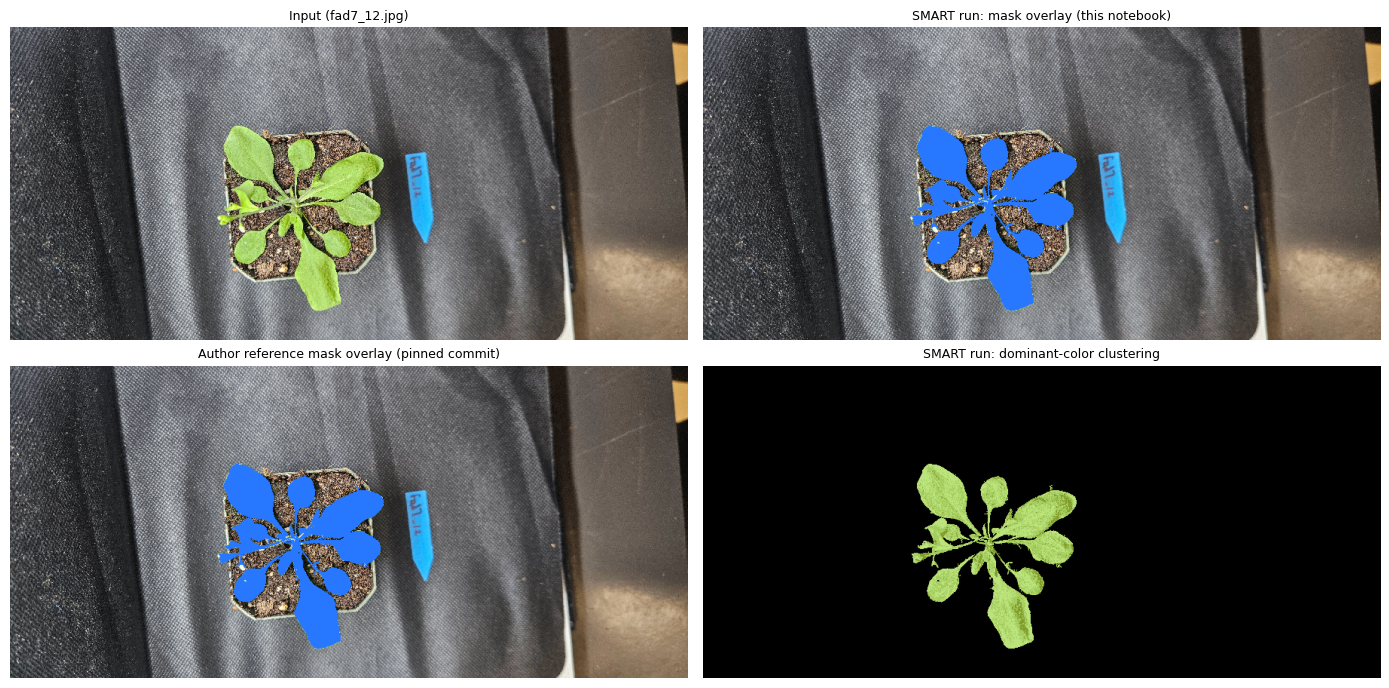

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt
rgb = cv2.cvtColor(cv2.imread("/content/smart_run/input/fad7_12.jpg"), cv2.COLOR_BGR2RGB)
our_mask = cv2.imread("/content/smart_run/results/fad7_12_mask.png", 0)
# fetch author reference mask once (dataset bytes -> Colab)
import urllib.request
data = urllib.request.urlopen(f"{RAW}/sample_test/results/fad7_12_mask.png").read()
open("/content/smart_run/author_mask.png", "wb").write(data)
aut_mask = cv2.imread("/content/smart_run/author_mask.png", 0)
clustered = cv2.cvtColor(cv2.imread("/content/smart_run/results/fad7_12_clustered.png"), cv2.COLOR_BGR2RGB)
scale = 900 / max(rgb.shape[:2])
def rs(im): return cv2.resize(im, (int(im.shape[1]*scale), int(im.shape[0]*scale)), interpolation=cv2.INTER_NEAREST)
panels = [("Input (fad7_12.jpg)", rgb),
          ("SMART run: mask overlay (this notebook)", None),
          ("Author reference mask overlay (pinned commit)", None),
          ("SMART run: dominant-color clustering", clustered)]
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, (title, im) in zip(axes.ravel(), panels):
    if im is None:
        base = rs(rgb).copy(); m = rs(our_mask) if "our" in title else rs(aut_mask)
        base[m > 0] = [255, 40, 40] if "our" in title else [40, 120, 255]
        im = base
    ax.imshow(rs(im) if im.shape[:2] != rs(rgb).shape[:2] else im)
    ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("/content/smart_run/results_figure.png", dpi=120); plt.show()

## Export a small CSV of the traits

Persist the run's trait row as CSV inside the Colab filesystem (`/content/smart_run/traits.csv`) so it can be downloaded from the Files panel. Japanese: 形質をCSVとして書き出します。

In [ ]:
import csv
with open("/content/smart_run/traits.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(rows[0]); w.writerow(rows[1])
print(open("/content/smart_run/traits.csv").read())

filename,leaf_area,solidity,max_width,max_height,compactness,longest_dimension,color_cluster_1_hex_value,color_cluster_1_ratio,color_cluster_1_difference,color_cluster_2_hex_value,color_cluster_2_ratio,color_cluster_2_difference,color_cluster_3_hex_value,color_cluster_3_ratio,color_cluster_3_difference
fad7_12.jpg,432800.5,0.5549297074890421,975,1089,0.8953168044077136,1185.971331862621,#bbe47d,0.46,164.76726502729,#a5cc5e,0.43,163.595390133889,#809d2b,0.11,156.8798611074016



## Interpretation and validation record

**What was executed:** the authors' unmodified (except the documented 3-line compatibility patch) SMART release pipeline on their bundled sample `fad7_12.jpg`, on a Colab CPU runtime. The run reproduced the paper's core image-analysis method: u2net-assisted plant-region extraction, parameter-free color-cluster segmentation of the rosette, geometrical trait computation, dominant-color clustering with CIE76 color differences, and watershed-based leaf counting.

**Agreement with the author's bundled reference** (`sample_test/results/` at the same commit): leaf area agrees to 0.03 % (432 800.5 vs 432 934.5 px), solidity to ~0.001, the three dominant-color hex values and their ratios match exactly, the CIE76 cluster differences match to ~1e-9, and the watershed leaf count (23) equals the reference `number_leaf`. `max_width`/`max_height` differ by ~0.4 %/9.5 %, consistent with the reference having been produced by an earlier library version (bounding geometry in OpenCV changed precision between versions); `longest_dimension` still agrees to 0.25 %.

**Not verified here:** the OPEN leaf device workflow, the paper's Fe/Zn treatment time-course experiments, and any dataset-level claims. One example is a plausibility demonstration, not a benchmark reproduction.

**検証の要約:** 著者同梱サンプルに対し面積0.03%差・優勢色一致・葉数23個一致。装置ワークフローと処理系実験は対象外です。

**References:** SMART repo (commit `7d3fe41`, BSD-3 per setup.py; repository LICENSE is GPL-3.0 — see report for the discrepancy note); OPEN leaf paper doi:10.1111/tpj.16449; u2net model via `rembg`.